# Signal processing
*Telemetry channels: a Kalman filter per channel, a spectral bin per lane, and a tone detector*

A spacecraft sends back many channels of attitude telemetry: a noisy angle from a star tracker and a noisy rate from a gyro. This page runs a Kalman filter on every channel at once, takes the filter's innovations (what the data say that the model did not expect), reads one spectral bin of them per lane with the Goertzel recursion, and uses the bin to detect a faint structural vibration. It checks the bins against NumPy's FFT, the false-alarm rate against theory, the detection rate against a closed form, and tunes the filter's process noise with the gradient of its likelihood.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The channel, once

The state of a channel is the angle `theta` and the rate `omega`, sampled every `dt = 0.1` s: `theta' = theta + dt omega`, `omega' = omega`, plus a random acceleration of strength `q`, whose covariance is `q [[dt^3/3, dt^2/2], [dt^2/2, dt]]`. Two sensors read the state with independent noise: the tracker's angle with a standard deviation of 0.01 rad, the gyro's rate with 0.002 rad/s. The model leaves out sensor bias, quantisation, dropouts and the dynamics of the spacecraft itself.

- A **Kalman filter** predicts the state, compares the prediction with the two readings, and corrects it. The **innovation** `y` is reading minus prediction. Its covariance is `S = P_predicted + R`, and when the model is right the innovations are white: no structure is left in them.
- A **spectral bin** is the sum of the signal against one complex exponential, `X_k = sum over n of u_n exp(-2 pi i k n / T)`. For `T = 256` samples, bin `k` is the frequency `k / (T dt)` Hz, which is 0.039 Hz times `k`. Here `u` is the first innovation, divided by its own standard deviation `sqrt(S_11)`, so it has variance 1.
- A **tone** that the filter cannot track, jitter of the tracker's mount at bin 40 (1.56 Hz) that only the tracker sees, shows up as a peak in the innovations' spectrum. When there is no tone, `|X_k|^2` of white unit-variance noise is exponentially distributed with mean `T`. That gives a detector: declare a tone when `|X_40|^2` is above `-T ln(P_fa)`, which a noise-only channel exceeds with probability `P_fa`.

Declare the words once as a `KernelKind`. One lane is one channel read at one bin: which channel (its row of the data) and which bin.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Int32, Kernel, Matrix, Mutable, Param, Scalar, Table
from hawk.diff import vjp
from hawk.ext import DATA_ONLY, KernelKind

DT, T, K0 = 0.1, 256, 40                                         # sample time (s), samples, the bin of the tone
R1, R2, Q_NOM = 0.01**2, 0.002**2, 1e-4                          # angle noise, rate noise, nominal acceleration strength
F_MAT = np.array([[1.0, DT], [0.0, 1.0]])
Q_MAT = np.array([[DT**3 / 3, DT**2 / 2], [DT**2 / 2, DT]])
P0_MAT = np.diag([1e-2, 1e-4])                                   # what the filter knows before the first reading


class Channel(KernelKind, slug="channel"):
    chan: Index         # which row of the data this lane reads
    bin_k: Scalar       # the spectral bin this lane reports
    t_stop: Scalar      # the lane uses the first t_stop samples of its channel
    guard = DATA_ONLY

Channel

__main__.Channel

## One lane: a Kalman filter and a bin

The kernel runs the filter through the 256 samples and, as it goes, feeds each normalised innovation to the Goertzel recursion `g_n = u_n + 2 cos(w) g_(n-1) - g_(n-2)` with `w = 2 pi k / T`. After the last sample `g_1^2 + g_2^2 - 2 cos(w) g_1 g_2` is `|X_k|^2`, with no table of sines and no FFT. It also writes the log-likelihood of the data under the filter, `sum of -(1/2)(y^T S^-1 y + ln det S + 2 ln 2 pi)`, and the mean of `y^T S^-1 y` per component, which is 1 for a consistent filter.

The per-lane algebra is `hawk.math` linear algebra on `Matrix[2, 2]`: `m.cholesky(S)` factors the innovation covariance, `m.cho_solve(L, ...)` solves with it for both the gain and the likelihood, and `info` adds up the status of every factorisation, so it is zero only when all of them succeeded. `F`, `Q0` and `P0` come in as matrix planes. The data are a `Table`, one row per channel, read at the lane's `chan`.

`t_stop` limits a lane to the first samples by feeding the recursion zeros after that; zeros do not change `X_k`, so the bin of a partial record is still exactly its DFT. That is what the animation uses.

In [4]:
@Channel
def monitor(chan, bin_k, t_stop, q: Scalar, F: Matrix[2, 2], Q0: Matrix[2, 2], P0: Matrix[2, 2], r1: Param, r2: Param,
            z: Table["row", "t":T, "s":2],
            power: Mutable[Scalar], loglik: Mutable[Scalar], nis: Mutable[Scalar], info: Mutable[Int32]):
    R = m.diag(m.vec(r1, r2))
    x = m.vec(0.0, 0.0)
    P = P0
    coeff = 2.0 * m.cos(6.283185307179586 * bin_k / 256.0)
    g1 = 0.0
    g2 = 0.0
    g0 = 0.0
    ll = 0.0
    chi = 0.0
    info = m.int32(0)                                                      # the sum of every factorisation's status: zero when all succeed
    for t in range(256):
        xp = F @ x                                                    # predict
        Pp = F @ P @ m.transpose(F) + q * Q0
        S = Pp + R
        L, bad = m.cholesky(S)                                        # the factor of the innovation covariance
        info = info + bad
        y = m.vec(z[chan, t, 0] - xp[0], z[chan, t, 1] - xp[1])       # the innovation
        a = m.cho_solve(L, y)                                         # S^-1 y
        quad = y[0] * a[0] + y[1] * a[1]
        ll = ll - 0.5 * (quad + m.log(m.det(S)) + 3.6757541328186907)
        chi = chi + quad
        u = m.where(t < t_stop, y[0] / m.sqrt(m.diagonal(S)[0]), 0.0)  # the normalised innovation, zero after the record ends
        g0 = u + coeff * g1 - g2                                      # Goertzel
        g2 = g1
        g1 = g0
        x = xp + Pp @ a                                               # correct: K y = P S^-1 y
        P = Pp - Pp @ m.cho_solve(L, Pp)
    power = g1 * g1 + g2 * g2 - coeff * g1 * g2
    loglik = ll
    nis = chi / 512.0


def plane(matrix, n):
    return np.tile(matrix.reshape(4, 1), (1, n))                  # a Matrix[2, 2] input is four planes, one lane per column


def simulate(n, q, rng, tone=0.0):
    # n channels of telemetry: the truth drawn from the model, the two sensors read it with noise, and an optional tone on the angle
    q = np.broadcast_to(q, (n,))
    chol_q = np.linalg.cholesky(Q_MAT)
    x = rng.multivariate_normal(np.zeros(2), P0_MAT, size=n)
    z = np.empty((n, T, 2))
    phase = rng.uniform(0, 2 * np.pi, n)
    amp = np.broadcast_to(tone, (n,))
    for t in range(T):
        x = x @ F_MAT.T + np.sqrt(q)[:, None] * (rng.normal(size=(n, 2)) @ chol_q.T)
        z[:, t, 0] = x[:, 0] + np.sqrt(R1) * rng.normal(size=n) + amp * np.sin(2 * np.pi * K0 * (t + 1) / T + phase)
        z[:, t, 1] = x[:, 1] + np.sqrt(R2) * rng.normal(size=n)
    return z


rng = np.random.default_rng(2)
monitor_run = eagle.deploy(monitor)


def run_monitor(z, bins, q=Q_NOM, t_stop=T, chan=None):
    n = len(bins)
    chan = np.arange(n, dtype=np.int32) if chan is None else np.asarray(chan, dtype=np.int32)
    return monitor_run.run(chan=chan, bin_k=np.asarray(bins, dtype=float), t_stop=np.broadcast_to(t_stop, (n,)) * 1.0, q=np.broadcast_to(q, (n,)) * 1.0,
                           F=plane(F_MAT, n), Q0=plane(Q_MAT, n), P0=plane(P0_MAT, n), r1=R1, r2=R2, z=z, returns="numpy")


z_demo = simulate(2, Q_NOM, rng, tone=np.array([0.0, 0.0]))
print("channels simulated:", z_demo.shape)

channels simulated: (2, 256, 2)


## Check it against what is known

The reference is the same filter written in NumPy, batched over channels, with `np.linalg.solve` for the 2 x 2 systems, and then NumPy's FFT of its first innovation. It shares no code with the kernel: a different solve, a different recursion, a different summation. The kernel's Goertzel power at every bin from 0 to 128 must equal the FFT's `|X_k|^2` of the same innovations, and its log-likelihood and consistency statistic must equal the NumPy filter's.

A tone is put into one of the two demo channels, at bin 40, with an amplitude of 0.006 rad, so that the check also covers a lane that sees a peak.

In [5]:
def numpy_filter(z, q=Q_NOM):
    # the Kalman filter in NumPy, batched: returns the normalised first innovations (T, channels), log-likelihood and mean y^T S^-1 y per component
    n = len(z)
    x = np.zeros((n, 2))
    P = np.broadcast_to(P0_MAT, (n, 2, 2)).copy()
    R = np.diag([R1, R2])
    q = np.broadcast_to(q, (n,))
    out, ll, chi = np.empty((T, n)), np.zeros(n), np.zeros(n)
    for t in range(T):
        xp = x @ F_MAT.T
        Pp = F_MAT @ P @ F_MAT.T + q[:, None, None] * Q_MAT
        S = Pp + R
        y = z[:, t, :] - xp
        a = np.linalg.solve(S, y[:, :, None])[:, :, 0]
        quad = (y * a).sum(axis=1)
        ll += -0.5 * (quad + np.log(np.linalg.det(S)) + 2 * np.log(2 * np.pi))
        chi += quad
        out[t] = y[:, 0] / np.sqrt(S[:, 0, 0])
        x = xp + np.einsum("nij,nj->ni", Pp, a)
        P = Pp - Pp @ np.linalg.solve(S, Pp)
    return out, ll, chi / (2 * T)


z_demo = simulate(2, Q_NOM, np.random.default_rng(4), tone=np.array([0.0, 0.006]))
bins = np.arange(129)
n_bins = len(bins)
lanes_chan = np.repeat(np.arange(2), n_bins)
spec = run_monitor(z_demo, np.tile(bins, 2), chan=lanes_chan)
power_kernel = spec["power"].reshape(2, n_bins)

u_ref, ll_ref, nis_ref = numpy_filter(z_demo)
power_fft = np.abs(np.fft.rfft(u_ref, axis=0)) ** 2                    # (129 bins, channels)
TOL_FFT = 1e-9
gap = np.abs(power_kernel - power_fft.T).max() / power_fft.max()
assert gap < TOL_FFT, gap
print(f"Goertzel bin power against NumPy's FFT of the same innovations: 2 channels x {n_bins} bins, worst gap {gap:.1e} of the largest < {TOL_FFT:g}")
first = lanes_chan == 0
assert np.allclose(spec["loglik"][::n_bins], ll_ref, rtol=1e-11) and np.allclose(spec["nis"][::n_bins], nis_ref, rtol=1e-11)
assert not np.any(spec["info"])
print(f"log-likelihood {spec['loglik'][::n_bins].round(2)} and consistency {spec['nis'][::n_bins].round(3)} equal the NumPy filter's; every factorisation succeeded")
print(f"the tone channel's bin {K0}: power {power_kernel[1, K0]:.0f} against a noise level of {T} (the clean channel: {power_kernel[0, K0]:.0f})")

Goertzel bin power against NumPy's FFT of the same innovations: 2 channels x 129 bins, worst gap 2.1e-14 of the largest < 1e-09
log-likelihood [1841.04 1828.91] and consistency [1.035 1.083] equal the NumPy filter's; every factorisation succeeded
the tone channel's bin 40: power 7779 against a noise level of 256 (the clean channel: 201)


## The false-alarm rate and the detection rate

A detector is only as good as its error rates, and for white Gaussian innovations both have closed forms.

**False alarms.** Run 4 096 noise-only channels, with a filter whose `q` is the truth, and count how many exceed the threshold `-T ln(P_fa)` at bin 40, for `P_fa = 0.01`. The count is binomial, so it must land within four standard deviations of `4096 P_fa`.

**Detections.** A tone of amplitude `A` on the angle reaches the innovation sequence after passing through the filter, which tracks some of it. The steady-state filter gives that gain exactly: its gain `K` solves the Riccati recursion, and the innovations are `Y(z) = [I - F z^-1 (I - (I - K) F z^-1)^-1 K] Z(z)` for a measurement `Z`. At `z = exp(2 pi i k / T)` its first component, divided by `sqrt(S_11)`, is the amplitude `a` the tone has in the unit-variance innovations. Then `2 |X|^2 / T` is a non-central chi-squared with two degrees of freedom and non-centrality `T a^2 / 2`, and the detection probability is its upper tail above `2 ln(1 / P_fa)`, a sum of Poisson-weighted central tails that fits in a few lines. Run 1 024 channels at each of five amplitudes and compare; the check allows four binomial standard deviations plus 3% for the start-up transient the steady state ignores.

In [6]:
P_FA = 0.01
THRESHOLD = -T * np.log(P_FA)

noise_only = simulate(4096, Q_NOM, np.random.default_rng(10))
alarms = (run_monitor(noise_only, np.full(4096, K0))["power"] > THRESHOLD).sum()
expected, sd = 4096 * P_FA, np.sqrt(4096 * P_FA * (1 - P_FA))
assert abs(alarms - expected) < 4 * sd, (alarms, expected, sd)
print(f"noise only: {alarms} false alarms in 4096 channels; expected {expected:.0f} +- {sd:.0f} at P_fa = {P_FA}")


def steady_state_gain(freq_bin):
    # amplitude a of a unit tone on the angle, in the unit-variance innovations, from the steady-state filter
    P = P0_MAT.copy()
    R = np.diag([R1, R2])
    for _ in range(5000):
        Pp = F_MAT @ P @ F_MAT.T + Q_NOM * Q_MAT
        S = Pp + R
        K = Pp @ np.linalg.inv(S)
        P = (np.eye(2) - K) @ Pp
    z_inv = np.exp(-2j * np.pi * freq_bin / T)
    I = np.eye(2)
    transfer = I - F_MAT * z_inv @ np.linalg.inv(I - (I - K) @ F_MAT * z_inv) @ K
    return abs(transfer[0, 0]) / np.sqrt(S[0, 0])


def detection_probability(lam, pfa=P_FA):
    # upper tail of a non-central chi-squared with two degrees of freedom: sum over j of Poisson(j; lam / 2) x central tail with 2 + 2 j
    x = 2.0 * np.log(1.0 / pfa)
    total, weight, term, partial = 0.0, np.exp(-lam / 2.0), 1.0, 0.0
    for j in range(300):
        partial += term                                              # the sum of (x / 2)^i / i! for i <= j
        total += weight * np.exp(-x / 2.0) * partial
        weight *= (lam / 2.0) / (j + 1)
        term *= (x / 2.0) / (j + 1)
    return total


gain = steady_state_gain(K0)
amplitudes = np.array([0.20, 0.25, 0.30, 0.35, 0.40]) / gain             # the tone amplitudes (rad) that give these gains a in the innovations
n_each = 1024
tone_z = np.concatenate([simulate(n_each, Q_NOM, np.random.default_rng(20 + i), tone=A) for i, A in enumerate(amplitudes)])
detected = (run_monitor(tone_z, np.full(len(tone_z), K0))["power"] > THRESHOLD).reshape(len(amplitudes), n_each)
rate = detected.mean(axis=1)
theory = np.array([detection_probability(T * (A * gain) ** 2 / 2.0) for A in amplitudes])
for A, r_, p_ in zip(amplitudes, rate, theory):
    print(f"tone {A * 1e3:.2f} mrad: detected {r_ * 100:5.1f}%, theory {p_ * 100:5.1f}%")
tol = 4 * np.sqrt(theory * (1 - theory) / n_each) + 0.03
assert (np.abs(rate - theory) < tol).all(), (rate, theory)
print(f"detection rate against the closed form at five amplitudes: within four binomial standard deviations and 3% (a tone of 1 rad reaches the innovations with an amplitude of {gain:.1f} standard deviations)")

noise only: 45 false alarms in 4096 channels; expected 41 +- 6 at P_fa = 0.01


tone 2.00 mrad: detected  28.8%, theory  28.2%
tone 2.50 mrad: detected  48.8%, theory  48.7%
tone 3.00 mrad: detected  71.1%, theory  69.8%
tone 3.50 mrad: detected  85.5%, theory  85.8%
tone 4.00 mrad: detected  94.6%, theory  94.8%
detection rate against the closed form at five amplitudes: within four binomial standard deviations and 3% (a tone of 1 rad reaches the innovations with an amplitude of 99.9 standard deviations)


## Tune the filter with the gradient of its likelihood

So far the filter knew the acceleration strength `q`. A real channel does not tell you. The log-likelihood of the data under the filter is a smooth function of `q`, and `hawk.diff.vjp(monitor, wrt=("q",))` gives its derivative for every channel in one reverse-mode launch, through the 256 steps of Cholesky factors and solves. 64 channels, each with its own true `q` between 0.3 and 3 times `Q_NOM`, start the filter at ten times `Q_NOM` and climb the likelihood in `ln q`, with a step length per lane that grows when a step helps and halves when it does not.

Three checks.
- **Exactness:** a central finite difference of the same log-likelihood, float64, relative step 1e-6; the derivative of exactly what the kernel computes, so a rounding tolerance.
- **The maximum:** the likelihood at the tuned `q` must be at least the likelihood at the true `q`, on every channel, since the climb is for the maximum of the data's own likelihood.
- **Consistency:** at the tuned `q` the mean of `y^T S^-1 y` per component must be 1, within four standard errors of the mean over channels (each is a chi-squared with 512 degrees of freedom).

In [7]:
monitor_vjp = Kernel("monitor_vjp", vjp(monitor, wrt=("q",)))
monitor_run, monitor_grad = eagle.deploy([monitor, monitor_vjp])


def loglik_and_grad(z, q):
    # log-likelihood of every channel, and its derivative with respect to q, in one forward and one reverse launch
    n = len(q)
    args = dict(chan=np.arange(n, dtype=np.int32), bin_k=np.zeros(n), t_stop=np.full(n, float(T)), q=q, F=plane(F_MAT, n), Q0=plane(Q_MAT, n),
                P0=plane(P0_MAT, n), r1=R1, r2=R2, z=z, returns="numpy")
    f = monitor_run.run(**args)
    g = monitor_grad.run(**args, bar_power=np.zeros(n), bar_loglik=np.ones(n), bar_nis=np.zeros(n), bar_info=np.zeros(n, dtype=np.int32))
    return f["loglik"], g, f["nis"]


rng = np.random.default_rng(31)
n_tune = 64
q_true = Q_NOM * np.exp(rng.uniform(np.log(0.3), np.log(3.0), n_tune))
z_tune = simulate(n_tune, q_true, rng)

ll, grad, _ = loglik_and_grad(z_tune, np.full(n_tune, Q_NOM))
rel = 1e-6
up = loglik_and_grad(z_tune, np.full(n_tune, Q_NOM * (1 + rel)))[0]
down = loglik_and_grad(z_tune, np.full(n_tune, Q_NOM * (1 - rel)))[0]
fd = (up - down) / (2 * rel * Q_NOM)
TOL_GRAD = 1e-6
gap = np.abs(grad - fd).max() / np.abs(fd).max()
assert gap < TOL_GRAD, gap
print(f"d loglik / d q against central differences on {n_tune} channels: worst gap {gap:.1e} of the largest value < {TOL_GRAD:g}")

ln_q = np.full(n_tune, np.log(10 * Q_NOM))
length = np.full(n_tune, 0.5)
f, g, _ = loglik_and_grad(z_tune, np.exp(ln_q))
trail_q = [ln_q.copy()]
for iteration in range(1, 200):
    slope = g * np.exp(ln_q)                                       # d loglik / d ln q
    trial = ln_q + length * np.sign(slope)
    f_new, g_new, _ = loglik_and_grad(z_tune, np.exp(trial))
    better = f_new > f
    ln_q, f, g = np.where(better, trial, ln_q), np.where(better, f_new, f), np.where(better[:], g_new, g)
    length = np.where(better, length * 1.2, length * 0.5)
    trail_q.append(ln_q.copy())
    if length.max() < 1e-4:
        break
q_fit = np.exp(ln_q)
print(f"{iteration} steps; the likelihood-maximising q is within a factor {np.exp(np.abs(np.log(q_fit / q_true)).mean()):.2f} of the truth on average")

ll_true, _, _ = loglik_and_grad(z_tune, q_true)
assert (f >= ll_true - 1e-6).all(), (f - ll_true).min()
print(f"the tuned likelihood is at least the likelihood at the true q on all {n_tune} channels (mean gain {np.mean(f - ll_true):.2f} nats)")

_, _, nis_fit = loglik_and_grad(z_tune, q_fit)
se_nis = np.sqrt(2 / 512 / n_tune)
assert abs(nis_fit.mean() - 1) < 4 * se_nis + 0.005, nis_fit.mean()
print(f"consistency at the tuned q: mean y^T S^-1 y per component {nis_fit.mean():.4f} (1 expected, standard error {se_nis:.4f})")

d loglik / d q against central differences on 64 channels: worst gap 1.0e-08 of the largest value < 1e-06


37 steps; the likelihood-maximising q is within a factor 1.14 of the truth on average
the tuned likelihood is at least the likelihood at the true q on all 64 channels (mean gain 0.65 nats)
consistency at the tuned q: mean y^T S^-1 y per component 0.9912 (1 expected, standard error 0.0078)


## The picture

Left: the spectrum of the innovations of the two demo channels, one point per bin, with the detection threshold. The clean channel's bins lie below the line except for the one or two in a hundred that a 1% false-alarm rate lets through; the channel with the tone has one bin far above it, at 1.56 Hz. The small crosses are NumPy's FFT of the same data, on top of the kernel's bins. Right: the detection probability against the tone's amplitude in the innovations, from the lanes (dots with their binomial error bars) and from the closed form (line), for a false-alarm probability of 1%.


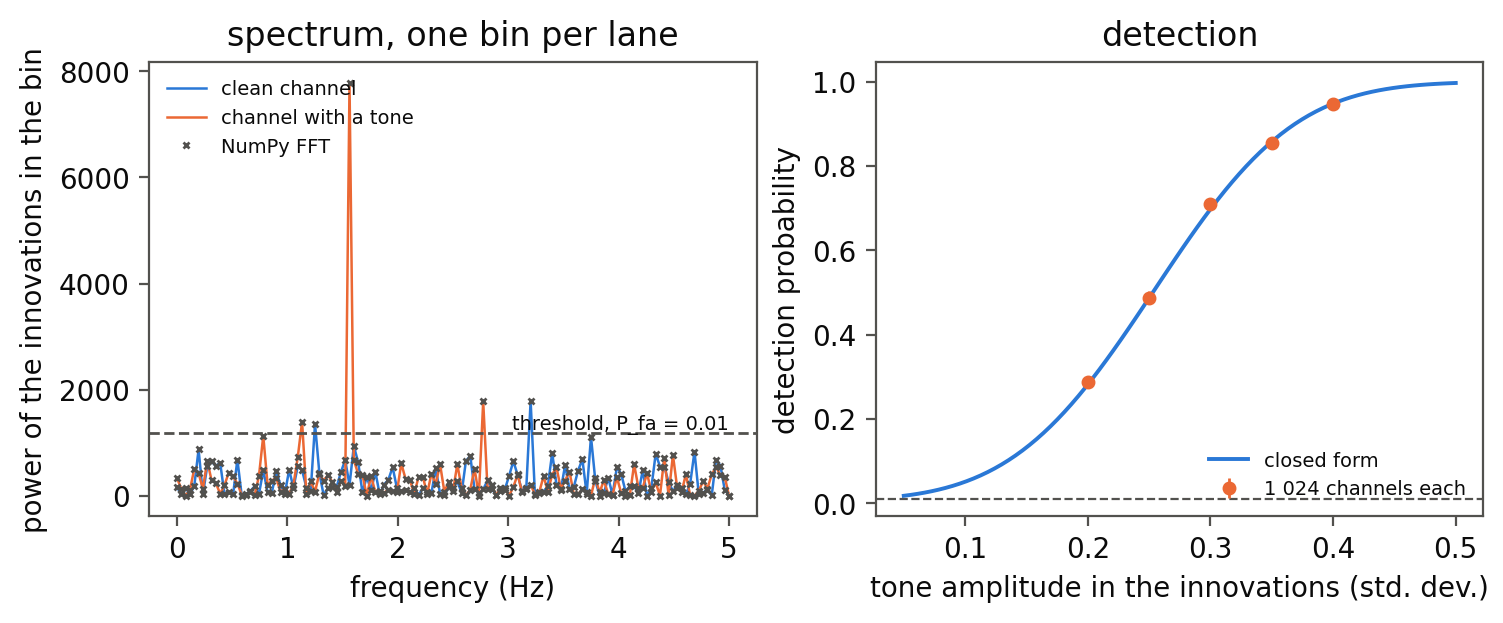
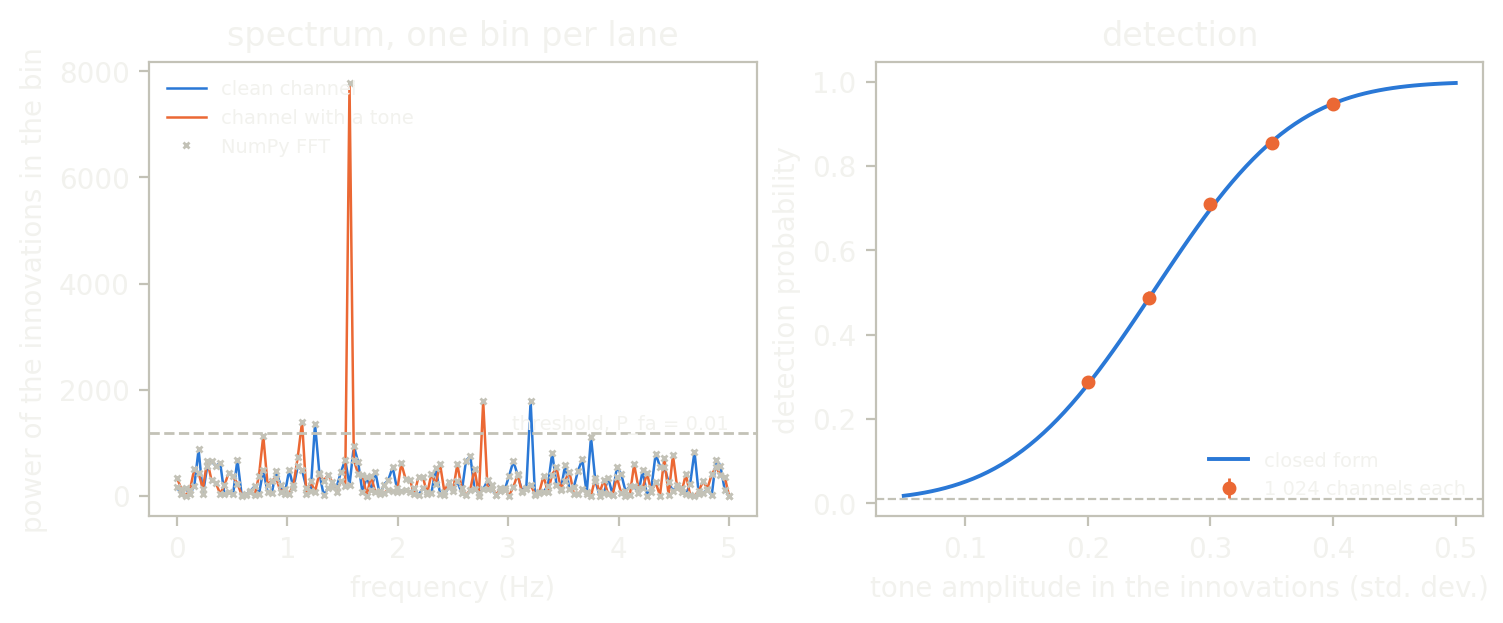

In [8]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834", "#3a9a6a"]
freq = bins / (T * DT)
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True)
left.plot(freq, power_kernel[0], lw=0.9, color=colours[0], label="clean channel")
left.plot(freq, power_kernel[1], lw=0.9, color=colours[1], label="channel with a tone")
left.plot(freq, power_fft[:, 0], "x", ms=2.5, color="#898781"); left.plot(freq, power_fft[:, 1], "x", ms=2.5, color="#898781", label="NumPy FFT")
left.axhline(THRESHOLD, color="#898781", ls="--", lw=1.0); left.text(freq[-1], THRESHOLD * 1.05, f"threshold, P_fa = {P_FA:g}", ha="right", fontsize=7, color="#898781")
left.set_xlabel("frequency (Hz)"); left.set_ylabel("power of the innovations in the bin"); left.set_title("spectrum, one bin per lane"); left.legend(frameon=False, fontsize=7, loc="upper left")

a_in = amplitudes * gain
fine = np.linspace(0.05, 0.5, 80)
right.plot(fine, [detection_probability(T * a * a / 2.0) for a in fine], lw=1.4, color=colours[0], label="closed form")
err = np.sqrt(theory * (1 - theory) / n_each)
right.errorbar(a_in, rate, yerr=err, fmt="o", ms=4, lw=1.0, color=colours[1], label="1 024 channels each")
right.axhline(P_FA, color="#898781", ls="--", lw=0.8)
right.set_xlabel("tone amplitude in the innovations (std. dev.)"); right.set_ylabel("detection probability"); right.set_title("detection"); right.legend(frameon=False, fontsize=7, loc="lower right")
show(fig, f"Two panels. Left: power of the innovations against frequency from 0 to {freq[-1]:.0f} hertz. The clean channel has {(power_kernel[0] > THRESHOLD).sum()} of {n_bins} bins above the threshold of {THRESHOLD:.0f}; the channel with a tone has one bin at {freq[K0]:.2f} hertz at {power_kernel[1, K0]:.0f}, far above it; NumPy's FFT crosses sit on the lanes' values. Right: detection probability rises from about {theory[0] * 100:.0f} to about {theory[-1] * 100:.0f} percent as the tone grows from {a_in[0]:.2f} to {a_in[-1]:.2f} standard deviations, and the measured points follow the closed-form line.")

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel runs through `eagle.deploy` on device arrays: 40 000 noise-only channels, so the false-alarm count has a standard error of about 20 and the rate must be 1% within four of them.

In [9]:
if gpu_available():
    big = 40_000
    z_big = xp.asarray(simulate(big, Q_NOM, np.random.default_rng(99)))
    out = monitor_run.run(chan=xp.arange(big, dtype=xp.int32), bin_k=xp.full(big, float(K0)), t_stop=xp.full(big, float(T)), q=xp.full(big, Q_NOM),
                          F=xp.asarray(plane(F_MAT, big)), Q0=xp.asarray(plane(Q_MAT, big)), P0=xp.asarray(plane(P0_MAT, big)), r1=R1, r2=R2, z=z_big)
    assert on_device(out["power"]), "the result is a device array: the kernel ran on the GPU"
    count = int((xp.asarray(out["power"]) > THRESHOLD).sum())
    assert abs(count - big * P_FA) < 4 * np.sqrt(big * P_FA * (1 - P_FA)), count
    print(f"{big} channels on the GPU: {count} false alarms, expected {big * P_FA:.0f} +- {np.sqrt(big * P_FA * (1 - P_FA)):.0f}")
else:
    print("no GPU here; the detector stays at 4096 channels")

40000 channels on the GPU: 407 false alarms, expected 400 +- 20


## The animation

The spectrum of the channel with the tone as the samples arrive. Each frame is one launch of lanes, one per bin, each reading only the first `n` samples (`t_stop = n`; `t_stop` is one value per lane, so one launch can also give every lane its own record length); the power is divided by `n`, so a noise bin averages 1 at every length and the line is the same threshold throughout. The bin of the tone grows with the record, and crosses the threshold when the tone has been in the data long enough. The helper that writes a looping GIF for a light page and one for a dark page is shared with the other domain pages.

In [10]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

lengths = list(range(16, T + 1, 8))
rows = []
for n in lengths:
    got = run_monitor(z_demo, bins, t_stop=n, chan=np.full(n_bins, 1))
    rows.append(np.asarray(got["power"]) / n)
rows = np.array(rows)                                             # (record length, bin)
assert np.allclose(rows[-1] * T, power_kernel[1]), "the full record is the spectrum above"
crossing = next((n for n, r in zip(lengths, rows) if r[K0] > -np.log(P_FA)), None)
print(f"the tone's bin crosses the threshold at {crossing} samples ({crossing * DT:.1f} s)" if crossing else "the tone's bin does not cross the threshold")


def render(theme, k):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 2.9), facecolor=pal["bg"])
    ax = fig.add_axes([0.13, 0.17, 0.83, 0.76], facecolor=pal["bg"])
    ax.axhline(-np.log(P_FA), color=pal["sub"], ls="--", lw=0.9)
    ax.text(freq[-1], -np.log(P_FA) * 1.04, "threshold", ha="right", fontsize=7, color=pal["sub"])
    ax.plot(freq, rows[k], lw=1.0, color="#2a78d6")
    ax.plot(freq[K0], rows[k][K0], "o", ms=4, color="#eb6834")
    ax.set_xlim(0, freq[-1]); ax.set_ylim(0, max(rows[:, K0].max() * 1.1, 8))
    ax.set_xlabel("frequency (Hz)", color=pal["sub"], fontsize=8); ax.set_ylabel("power in the bin / samples so far", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    ax.text(0.03, 0.9, f"{lengths[k]} samples = {lengths[k] * DT:.1f} s", transform=ax.transAxes, fontsize=8, color=pal["ink"])
    return frame_of(fig, pal["bg"])


sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, k) for k in range(len(lengths))] + [render(theme, len(lengths) - 1)] * 8, f"tone_detection_{theme}", fps=8))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

the tone's bin crosses the threshold at 72 samples (7.2 s)


tone_detection_light.gif 299 kB
tone_detection_dark.gif 302 kB


```{image} ../../_static/anim/tone_detection_light.gif
:class: only-light
:alt: Power of the innovations against frequency, one line, recomputed as the record grows from 16 to 256 samples: the noise bins jitter around 1, and one orange dot at 1.56 hertz climbs steadily above a dashed threshold line as more samples arrive.
```
```{image} ../../_static/anim/tone_detection_dark.gif
:class: only-dark
:alt: Power of the innovations against frequency, one line, recomputed as the record grows from 16 to 256 samples: the noise bins jitter around 1, and one orange dot at 1.56 hertz climbs steadily above a dashed threshold line as more samples arrive.
```

## What just happened

- `Channel` named the data row, the bin and the length of record once; `monitor` is a Kalman filter and a Goertzel bin in those names, one lane per channel and bin, with `m.cholesky` and `m.cho_solve` doing the 2 x 2 algebra per lane.
- The bins equalled NumPy's FFT of a separately written NumPy filter's innovations to rounding, and so did the likelihood.
- The detector's false-alarm count matched `4096 P_fa` within binomial error, and its detection rate matched the closed form built from the steady-state filter at five amplitudes.
- `vjp` gave the likelihood's derivative with respect to `q` on every channel in one launch, through the 256 factorisations; it matched a finite difference to rounding, and the climb found a likelihood at least that of the true `q` on all 64 channels, with a consistent filter.

## Try this

Move the tone to another bin, `K0 = 12`, and watch the filter pass more of it into the innovations: the steady-state gain printed above changes, and so does the detection rate, as the closed form says. Or put a bias on the rate sensor and see the consistency statistic leave 1, which is the cue that the model is wrong.

## Next

[Control](21_control) is the other place a state is estimated and a gain tuned. [Finance](18_finance) takes derivatives of a simulation through reverse mode on the same footing.